# 24 — LTN v5: facts file, SymMedNet knowledge base, plan of 6 November

Code: folder `ltn_v5` (`ltn_attributes.py`, `ltn_logic.py`, `ltn_heads.py`, `train_frcnn.py`, `build_facts.py`).
Plan agreed in the call of 6 Nov: every loss is **1 − Sat**; no Normal class; the 16 axioms of SymMedNet without the
Normal ones (ψ3–ψ14, ψ16 = `kb16`), written as in the paper; facts φ1–φ21; one seed (1337); two baselines,
**G** and **G+V**, 50 epochs.

| Step | Run | Class facts | Concept facts φ1–φ21 | Axioms ψ |
|---|---|---|---|---|
| 0 | G, G+V (done) | cross-entropy | – | – |
| 1 | **S0** = the baseline converted to LTN | 1 − Sat | – | – |
| 2 | **C** | 1 − Sat | ✓ | – |
| 3 | **AxC** | 1 − Sat | ✓ | ✓ |
| 4 | **Ax** | 1 − Sat | – | ✓ |

Block 1 runs S0 with the two aggregators that keep 1 − Sat in a detector (geo, balanced) and chooses one;
block 2 runs C, AxC, Ax with it. Each cell stops with an error if something is wrong: fix it before the next one.

| Section | What | Time |
|---|---|---|
| 0 | setup (also unloads any older ltn modules: no kernel restart needed) | seconds |
| 1–2 | unit tests (CPU) | ~2 min |
| 3 | build the facts file `facts_v5.csv` and check it | ~1 min |
| 4 | the knowledge base as it is trained (text for the supervisor) | seconds |
| 5 | smoke runs, 1 epoch | ~15 min |
| 6 | **block 1**: S0 geo / balanced on G and G+V (4 runs) | ~7 h (2 at once) |
| 7 | choice of the aggregator (stops if neither keeps detection) | seconds |
| 8 | **block 2**: C, AxC, Ax on G and G+V (6 runs) | ~10 h (2 at once) |
| 9 | results | seconds |
| 10 | concept evaluation and examples (C, AxC, Ax; validation) | ~15 min |

### Notes for the reader
* The notebook was run on the lab machine (Windows, shared GPU) in several kernel sessions (the training blocks run
  overnight), so execution counts restart between blocks; every output shown is the one of the actual runs.
* Training cells (5, 6, 8) start `train_frcnn.py` as subprocesses: their output is only the launcher's summary (start,
  end, the `LTN` lines of the log). Full logs: `F:\runs\<run>.console.log`, per-epoch metrics in
  `F:\runs\<run>\history.json`, and W&B.
* Validation split only; the test split is never read (the facts file refuses test rows; the evaluation reads only the validation split).
* One seed (1337): differences of about ±0.01 mAP@50 are within run-to-run noise.
* Where to look in the code: `README.md` (paper → code map).

## 0. Setup

In [1]:
import os, sys, json, glob, importlib, subprocess, time
import numpy as np, pandas as pd

# ---- paths of the lab machine (Windows); change only these lines to run elsewhere ----
CODE_DIR   = r"C:\Users\grains7lab2\Desktop\Tesi_Karimov\code\ltn_v5"
DATA_ROOT  = r"F:\MammoLTN-full-images"
SPLITS_DIR = "CBIS_08_11_2024"                                   # split file and CBIS CSVs (as train_frcnn.py)
PNG_DIR    = "CBIS-DDSM-PNG16-CROPPED-MASKS"
XLSX_NAME  = "cbis_ddsm_image_level_combined.xlsx"
OUT_ROOT   = r"F:\runs"
FACTS_FILE = os.path.join(OUT_ROOT, "facts_v5", "facts_v5.csv")   # written in section 3, read by every LTN run
SCRIPT     = os.path.join(CODE_DIR, "train_frcnn.py")
# the two cross-entropy baselines (augmentation recipes E45 and E45+V): every LTN run starts from their config
BASES      = {"G": "E45_e100_step60", "GV": "E45+V_e50"}          # baselines with cross-entropy (already trained)
EPOCHS, SEED = 50, 1337
MEAN_FROM  = 10                                                  # mean of validation mAP@50 over epochs 10-49

# use ONLY the v5 modules: drop other ltn folders from the path and unload modules imported before
sys.path = [p for p in sys.path if not os.path.basename(p.rstrip("\\/")).startswith("ltn_v")]
sys.path.insert(0, CODE_DIR)
for m in ("ltn_attributes", "ltn_logic", "ltn_heads", "test_ltn", "test_ltn_heads", "build_facts"):
    sys.modules.pop(m, None)
os.chdir(CODE_DIR)
import ltn_attributes as A, ltn_logic as L, ltn_heads as H
for m in (A, L, H):
    assert m.VERSION == 5 and os.path.dirname(os.path.abspath(m.__file__)) == os.path.abspath(CODE_DIR), \
        f"{m.__name__} is not the v5 file of CODE_DIR: {m.__file__}"
with open(SCRIPT, encoding="utf-8") as f:
    assert "ltn_facts_file" in f.read(), "train_frcnn.py in CODE_DIR is not version 5"
# every input file must exist before anything starts
need = [os.path.join(DATA_ROOT, SPLITS_DIR, XLSX_NAME), os.path.join(DATA_ROOT, PNG_DIR, "manifest.csv"),
        os.path.join(CODE_DIR, "build_facts.py")] + \
       [os.path.join(OUT_ROOT, b, f) for b in BASES.values() for f in ("run_manifest.json", "history.json")]
for p in need:
    print(("ok      " if os.path.exists(p) else "MISSING "), p)
assert all(os.path.exists(p) for p in need), "a file is missing (see above)"
print("\nsetup ok - code v5 from", CODE_DIR)

ok       F:\MammoLTN-full-images\CBIS_08_11_2024\cbis_ddsm_image_level_combined.xlsx
ok       F:\MammoLTN-full-images\CBIS-DDSM-PNG16-CROPPED-MASKS\manifest.csv
ok       C:\Users\grains7lab2\Desktop\Tesi_Karimov\code\ltn_v5\build_facts.py
ok       F:\runs\E45_e100_step60\run_manifest.json
ok       F:\runs\E45_e100_step60\history.json
ok       F:\runs\E45+V_e50\run_manifest.json
ok       F:\runs\E45+V_e50\history.json

setup ok - code v5 from C:\Users\grains7lab2\Desktop\Tesi_Karimov\code\ltn_v5


## 1. Unit tests of the logic, the facts and the facts file (CPU, no data)

In [2]:
# runs every test_* function of a test module (no pytest needed on the lab machine)
def run_tests(module_name):
    sys.modules.pop(module_name, None)
    mod = importlib.import_module(module_name)
    tests = [(k, v) for k, v in vars(mod).items() if k.startswith("test_") and callable(v)]
    for name, fn in tests:
        fn()
        print(f"ok   {name}")
    print(f"\n{len(tests)} tests passed ({module_name})")
    return len(tests)

N1 = run_tests("test_ltn")

ok   test_connectives_are_classical_on_0_1
ok   test_implication_example_of_the_thesis
ok   test_apme_p1_is_the_mean
ok   test_apme_large_p_approaches_the_minimum
ok   test_apme_satisfied_formula_has_finite_gradient
ok   test_apme_empty_domain_is_vacuous
ok   test_p_schedule_follows_symmednet
ok   test_class_facts_ce_is_the_baseline_cross_entropy
ok   test_class_facts_sat_is_apme_of_the_labelled_class
ok   test_class_facts_geo_is_one_minus_exp_minus_ce
ok   test_geo_keeps_the_gradient_on_a_badly_classified_lesion
ok   test_balanced_weights_background_and_lesions
ok   test_class_facts_sat_gradient_raises_the_labelled_class
ok   test_class_and_finding_predicates_are_sums_of_the_softmax
ok   test_softmax_compound_is_a_disjunction
ok   test_sigmoid_facts_are_one_per_value_with_negatives
ok   test_heads_of_version_5
ok   test_axioms_are_written_as_in_the_paper
ok   test_the_sixteen_axioms_of_symmednet_without_normal
ok   test_every_axiom_is_well_formed
ok   test_a_constant_of_another_predic

C:\Users\grains7lab2\Desktop\Tesi_Karimov\code\ltn_v5\test_ltn.py:119: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  assert close(L.class_facts_sat(logits[:10], only_bg, 2.0, "balanced"), L.apme(t[:0].new_tensor(


ok   test_facts_file_refuses_test_rows_and_bad_cells

47 tests passed (test_ltn)


## 2. The LTN heads on a real Faster R-CNN (CPU, random weights, ~1 min)

In [3]:
N2 = run_tests("test_ltn_heads")

ok   test_l0_losses_are_identical_to_torchvision
ok   test_l0_detections_are_identical_to_torchvision
ok   test_concept_targets_follow_the_matched_lesion
ok   test_class_facts_as_sat_replace_only_the_classifier_loss
ok   test_ax_trains_without_concept_labels
ok   test_ax_c_trains_every_head
ok   test_ax_aux_adds_the_three_regularisers
ok   test_bc_uses_cross_entropy_only
ok   test_missing_concept_targets_raise
ok   test_inference_returns_concepts_per_detection
ok   test_bad_values_are_refused
ok   test_install_as_called_by_train_frcnn

12 tests passed (test_ltn_heads)


## 3. The facts file
`build_facts.py` writes `facts_v5.csv`: one row per lesion of the **train and validation** split (the test split is
never read), one column per fact (`phi01_has_mass` … `phi21_distr_diffuse`; 1 = true, 0 = false, empty = unknown),
plus the raw CBIS strings. Every LTN run reads its facts only from this file. Expected (as in v4): train ≈ 2,350
lesions, val ≈ 470; the join check (pathology of the CBIS row = image label) above 97 %.

In [4]:
# writes F:\runs\facts_v5\facts_v5.csv (+ _summary.csv) from the split file, the mask manifest and the CBIS CSVs
r = subprocess.run([sys.executable, os.path.join(CODE_DIR, "build_facts.py"), "--data_root", DATA_ROOT,
                    "--png_dir_name", PNG_DIR, "--splits_dir_name", SPLITS_DIR, "--combined_xlsx_name", XLSX_NAME,
                    "--out", FACTS_FILE], capture_output=True, text=True)
print(r.stdout); print(r.stderr[-3000:])
assert r.returncode == 0, "build_facts.py failed (see above)"

# read it back with the same reader as train_frcnn.py (it refuses test rows)
facts = A.load_facts_file(FACTS_FILE)                      # the same reader as train_frcnn.py
df = pd.read_csv(FACTS_FILE, keep_default_na=False)
assert set(df["split"]) <= {"train", "val"}
summ = pd.read_csv(os.path.splitext(FACTS_FILE)[0] + "_summary.csv")
display(summ.pivot(index="fact", columns="split", values=["known", "true"]))
# lesions with a fact, per head and split
per_head = {sp: {h: sum(v["attrs"] is not None and v["attrs"][h] is not None for k, v in facts.items() if v["split"] == sp)
                 for h in A.HEAD_NAMES} for sp in ("train", "val")}
display(pd.DataFrame(per_head).T)
assert per_head["train"]["calc_morph"] > 1000 and per_head["train"]["mass_margin"] > 800, "too few facts: wrong CSVs?"
display(df.head(5))

CBIS CSV rows kept (train/val images): {'mass_case_description_train_set.csv': 1301, 'calc_case_description_train_set.csv': 1533}
train: 2352 lesions on 1990 images | 49 without a CBIS row | masses 1044, calcifications 1308
val: 468 lesions on 429 images | 5 without a CBIS row | masses 215, calcifications 253
check of the join: pathology of the CBIS row = image label for 99.6% of 2766 lesions

written F:\runs\facts_v5\facts_v5.csv (2820 rows) and its _summary.csv




known       true     
split                             train  val train  val
fact                                                   
phi01_has_mass                     2352  468  1044  215
phi02_has_calc                     2352  468  1308  253
phi03_density_high                  910  207   278   86
phi03_density_low                   910  207   632  121
phi04_shape_oval                    903  186   480  102
phi05_shape_round                   903  186   105   18
phi06_shape_irregular               903  186   319   69
phi07_margin_circumscribed          986  206   285   55
phi08_margin_obscured               986  206   161   45
phi09_margin_microlobulated         986  206    86   18
phi10_margin_indistinct             986  206   295   50
phi11_margin_spiculated             986  206   252   57
phi12_morph_typically_benign       1262  251   539   66
phi13_morph_coarse_heterogeneous   1262  251     0    0
phi14_morph_pleomorphic            1262  251   582  151
phi15_morph_amorphous              1262  251   126   30
phi16_morph_fine_linear_branching  1262  251    93   18
phi17_distr_clustered               946  212   586  142
phi18_distr_segmental               946  212   146   32
phi19_distr_linear                  946  212    92   23
phi20_distr_regional                946  212    85   15
phi21_distr_diffuse                 946  212    37    0

,mass_shape,mass_margin,mass_density,calc_morph,calc_distr
train,903,986,910,1262,946
val,186,206,207,251,212


,image_id,lesion_id,split,family,pathology,n_lesions_image,in_cbis_csv,cbis_shape,cbis_margin,cbis_calc_type,...,phi12_morph_typically_benign,phi13_morph_coarse_heterogeneous,phi14_morph_pleomorphic,phi15_morph_amorphous,phi16_morph_fine_linear_branching,phi17_distr_clustered,phi18_distr_segmental,phi19_distr_linear,phi20_distr_regional,phi21_distr_diffuse
0,Calc-Test_P_00041_LEFT_CC,2,train,CALC,BENIGN,1,False,,,,...,,,,,,,,,,
1,Calc-Test_P_00041_LEFT_MLO,2,train,CALC,BENIGN,1,False,,,,...,,,,,,,,,,
2,Calc-Test_P_00495_RIGHT_CC,2,train,CALC,BENIGN,2,False,,,,...,,,,,,,,,,
3,Calc-Test_P_00495_RIGHT_CC,3,train,CALC,BENIGN,2,False,,,,...,,,,,,,,,,
4,Calc-Test_P_00495_RIGHT_MLO,1,train,CALC,BENIGN,2,False,,,,...,,,,,,,,,,


## 4. The knowledge base as it is trained
Text for the supervisor (same as the `LTN` lines at the start of every run's log). Groundings in the detector:
`isOfClass(x, ℓ_Malignant)` = p(mass malignant) + p(calc malignant), `has_mass(x, c_mass)` = p(mass benign) +
p(mass malignant), concept atoms = the component of the concept head (see `ltn_logic.py`, docstring).

In [5]:
# the formulas exactly as trained; the axiom lines are also printed at the start of every run log
print("Class facts:   phi_class = forall Diag(x, l_k). isOfClass(x, l_k)          (loss_class_sat = 1 - Sat)")
print("Finding facts: phi1 = forall Diag(x, l_mass). has_mass(x, c_mass);  phi2 = forall Diag(x, l_calc). has_calc(x, c_calc)")
print("Concept facts: phi3-phi21 = forall Diag(x, l_a). has_attr(x, l_a)        (columns of the facts file)\n")
for a in L.AXIOM_SETS["kb16"]:
    print(L.axiom_text(a))

Class facts:   phi_class = forall Diag(x, l_k). isOfClass(x, l_k)          (loss_class_sat = 1 - Sat)
Finding facts: phi1 = forall Diag(x, l_mass). has_mass(x, c_mass);  phi2 = forall Diag(x, l_calc). has_calc(x, c_calc)
Concept facts: phi3-phi21 = forall Diag(x, l_a). has_attr(x, l_a)        (columns of the facts file)

psi3: forall x Diag(x, l_Benign): has_mass(x, c_mass) and (has_margin(x, c_margin_obs) or has_margin(x, c_margin_circ)) => isOfClass(x, l_Benign)
psi4: forall x Diag(x, l_Malignant): has_mass(x, c_mass) and has_margin(x, c_margin_ml) => isOfClass(x, l_Malignant)
psi5: forall x Diag(x, l_Malignant): has_mass(x, c_mass) and has_margin(x, c_margin_ind) => isOfClass(x, l_Malignant)
psi6: forall x Diag(x, l_Malignant): has_mass(x, c_mass) and has_shape(x, c_shape_ir) => isOfClass(x, l_Malignant)
psi7: forall x Diag(x, l_Malignant): has_calc(x, c_calc) and has_morphology(x, c_morph_amo) and not has_distribution(x, c_distr_reg) and not has_distribution(x, c_distr_dif) => isOf

## 5. Smoke runs (GPU, 1 epoch each, ~15 min)
Only to see that the variants start and log. Look for `file dei fatti: … lesioni`, the `LTN v5` line, the axioms in
the paper's notation, the `LTN val` line, and `exit 0`.

In [5]:
# ---- flags of train_frcnn.py for every variant of the plan ----
# COMMON: LTN heads on, ApME p = 2 fixed, every term weighted by the share of regions in its domain
COMMON = {"ltn": "true", "ltn_norm": "region", "ltn_p": "2"}          # recipe of v3/v4: p = 2, terms weighted by domain
# C: concept facts phi1-phi21 read from the facts file
FACTS  = {"ltn_attrs": "true", "ltn_facts_file": FACTS_FILE, "ltn_attr_loss": "facts"}
# Ax: the 13 axioms kb16, Diag guard on the class (as the paper), has_mass / has_calc predicted
AXIOMS = {"ltn_axioms": "kb16", "ltn_ax_guard": "class", "ltn_ax_family": "pred"}

# S0: class facts as 1 - Sat with the given aggregator (geo or balanced)
def sat(agg):
    d = {**COMMON, "ltn_class_loss": "sat", "ltn_class_agg": agg}
    return {**d, "ltn_class_bg_w": "0.5"} if agg == "balanced" else d

def flags(step, agg):
    return {"S0": sat(agg), "C": {**sat(agg), **FACTS}, "AxC": {**sat(agg), **FACTS, **AXIOMS},
            "Ax": {**sat(agg), **AXIOMS}}[step]

# e.g. v5_GV_AxC_geo_e50 = folder name in F:\runs
def run_name(base, step, agg, epochs=EPOCHS):
    return f"v5_{base}_{step}_{agg}_e{epochs}"

# lines of a run's console log shown here when it finishes
SHOW = ("file dei fatti", "fatti BI-RADS", "LTN ", "Traceback", "Error", "mAP@50 ")

# command line of one run: hyper-parameters, data and augmentation from the baseline's run_manifest.json;
# lr_step_size 60 > 50 epochs = constant lr within the run; patience 0 = no early stopping (all 50 epochs)
def _args(name, extra, epochs, seed, base):
    args = [sys.executable, SCRIPT, "--config", os.path.join(OUT_ROOT, BASES[base], "run_manifest.json"),
            "--run_name", name, "--seed", str(seed), "--epochs", str(epochs), "--lr_step_size", "60", "--patience", "0"]
    for k, v in extra.items():
        args += [f"--{k}", v]
    return args

def _report(name, rc):
    log = os.path.join(OUT_ROOT, name + ".console.log")
    with open(log, encoding="utf-8", errors="replace") as f:
        lines = [l for l in f.read().splitlines() if any(s in l for s in SHOW)]
    for l in lines[:20] + (["    ..."] + lines[-3:] if len(lines) > 23 else []):
        print("   ", l[-300:])
    print(f"   {name}: exit {rc}  (log: {log})", flush=True)

# runs the jobs as subprocesses, at most max_parallel at a time on the GPU
def launch_all(jobs, max_parallel=2):
    """jobs = [(name, flags, epochs, seed, base)]. Runs that already have best.pt are skipped."""
    todo = [j for j in jobs if not os.path.exists(os.path.join(OUT_ROOT, j[0], "best.pt"))]
    for j in jobs:
        if j not in todo:
            print(f"skip {j[0]}: already exists")
    running, codes = [], {}
    while todo or running:
        while todo and len(running) < max_parallel:
            name, extra, epochs, seed, base = todo.pop(0)
            f = open(os.path.join(OUT_ROOT, name + ".console.log"), "w", encoding="utf-8")
            p = subprocess.Popen(_args(name, extra, epochs, seed, base), stdout=f, stderr=subprocess.STDOUT)
            running.append((name, p, f))
            print(f"-> {name} started {time.strftime('%H:%M')}", flush=True)
            time.sleep(60)                     # let it load the data and take its GPU memory before the next one
        for item in list(running):
            name, p, f = item
            if p.poll() is not None:
                f.close(); running.remove(item); codes[name] = p.returncode
                print(f"<- {name} finished {time.strftime('%H:%M')}", flush=True)
                _report(name, p.returncode)
        time.sleep(20)
    bad = {k: v for k, v in codes.items() if v != 0}
    assert not bad, f"runs failed: {bad} - send the console logs"
    return codes

# smoke test: 1 epoch of two variants (skipped if they exist)
assert os.path.exists(FACTS_FILE), "run section 3 first (the facts file)"
launch_all([("v5_smoke_S0_geo_e1", flags("S0", "geo"), 1, SEED, "G"),
            ("v5_smoke_AxC_bal_e1", flags("AxC", "balanced"), 1, SEED, "GV")])

skip v5_smoke_S0_geo_e1: already exists
skip v5_smoke_AxC_bal_e1: already exists


{}

## 6. Block 1: the baseline converted to LTN (S0), two aggregators, on G and G+V (4 runs, 50 epochs, seed 1337)
The class facts as 1 − Sat with one ApME clause lost the calcifications (runs of 4 Nov). The two aggregators below keep
1 − Sat and are tested here: **geo** (geometric mean = product over the regions, as Faster-LTN; 1 − Sat = 1 − exp(−CE))
and **balanced** (ApME, background 1/2, each lesion class 1/8, SymMedNet's batch balance). `MAX_PARALLEL = 2` runs two
at a time (≈ 2 × 6 GB); 1 on a busy GPU. Finished runs are skipped: the cell can be re-run after an interruption
(delete the folder of a run stopped half-way).

In [7]:
# 4 runs: S0 with geo and balanced, on G and G+V (output = launcher summary; full logs in F:\runs)
MAX_PARALLEL = 2
AGGS = ("geo", "balanced")
launch_all([(run_name(b, "S0", a), flags("S0", a), EPOCHS, SEED, b) for a in AGGS for b in BASES], MAX_PARALLEL)

-> v5_G_S0_geo_e50 started 23:37
-> v5_GV_S0_geo_e50 started 23:38
<- v5_G_S0_geo_e50 finished 02:54
    LTN v5     class_loss=sat (agg geo)  attr_loss=none  axioms=-  ax_guard=class  ax_family=pred  aux=-  norm=region  heads=no  weights={'class': 1.0, 'find': 1.0, 'attr': 1.0, 'clin': 1.0, 'ent': 1.0, 'kl': 1.0, 'rec': 1.0}
    LTN        p=2
    epoca   0 | train 0.2050 | val 0.1720 | mAP@50 0.0940 | FROC massa 0.4921 (0.5100 dedup) | calc 0.0959 (0.0965 dedup) | AUC 0.5116 | 243s  <-- best
              LTN val | ce_class 0.071 | loss_class_sat 0.069 | sat_class 0.931
    epoca   1 | train 0.1753 | val 0.1642 | mAP@50 0.1257 | FROC massa 0.5638 (0.5873 dedup) | calc 0.0965 (0.0965 dedup) | AUC 0.5621 | 213s  <-- best
              LTN val | ce_class 0.071 | loss_class_sat 0.068 | sat_class 0.932
    epoca   2 | train 0.1681 | val 0.1620 | mAP@50 0.1464 | FROC massa 0.6280 (0.6460 dedup) | calc 0.1231 (0.1231 dedup) | AUC 0.5739 | 204s  <-- best
              LTN val | ce_class 0.069

{'v5_G_S0_geo_e50': 0,
 'v5_GV_S0_geo_e50': 0,
 'v5_G_S0_balanced_e50': 0,
 'v5_GV_S0_balanced_e50': 0}

## 7. Choice of the aggregator
For each run: best validation mAP@50 within 50 epochs and the mean over epochs 10–49 (less noisy), against the
baseline of the same family (G cut at 50 epochs; G+V). The aggregator with the higher mean Δ over G and G+V is kept for
block 2. **Gate:** if even the best one loses more than 0.015 on the mean, the cell stops — send the table.

In [8]:
# validation history of a run, cut at 50 epochs (G was trained for 100)
def hist(run, cut=EPOCHS):
    with open(os.path.join(OUT_ROOT, run, "history.json"), encoding="utf-8") as f:
        return [h for h in json.load(f) if "val/map_50" in h and h["epoch"] < cut]

# best epoch + means over epochs 10-49 (less noisy than the best epoch)
def summary_row(label, run, base):
    h = hist(run)
    b = max(h, key=lambda r: r["val/map_50"])
    mid = [r for r in h if r["epoch"] >= MEAN_FROM]
    m = lambda k: float(np.mean([r[k] for r in mid])) if mid else np.nan
    return dict(run=label, base=base, folder=run, best_epoch=b["epoch"], mAP50_best=b["val/map_50"],
                mAP50_mean=m("val/map_50"), FROCmass_mean=m("val/froc_mass_mean"), FROCcalc_mean=m("val/froc_calc_mean"),
                AUC_mean=m("val/image_auc_malignancy"), det_mean=m("val/n_detections"))

ref = {b: summary_row(f"{b} (CE)", BASES[b], b) for b in BASES}
rows = [ref[b] for b in BASES]
for a in AGGS:
    for b in BASES:
        rows.append(summary_row(f"S0 {a}", run_name(b, "S0", a), b))
t = pd.DataFrame(rows)
for k in ("mAP50_best", "mAP50_mean", "FROCcalc_mean"):
    t[f"d_{k}"] = t.apply(lambda r: r[k] - ref[r.base][k], axis=1)
display(t.round(4))
# aggregator chosen by the mean delta of mAP@50 over G and G+V; saved for block 2
score = {a: float(t[t.run == f"S0 {a}"]["d_mAP50_mean"].mean()) for a in AGGS}
AGG = max(score, key=score.get)
print("mean delta of mAP@50 (epochs 10-49) over G and G+V:", {k: round(v, 4) for k, v in score.items()})
json.dump(dict(chosen=AGG, score=score, time=time.strftime("%Y-%m-%d %H:%M")),
          open(os.path.join(OUT_ROOT, "v5_chosen_aggregator.json"), "w"), indent=1)
t.to_csv(os.path.join(OUT_ROOT, "v5_block1.csv"), index=False)
assert score[AGG] > -0.015, f"neither aggregator keeps detection (best {AGG}: {score[AGG]:+.4f}): stop, send v5_block1.csv"
print(f"\nchosen aggregator: {AGG}  (saved in v5_chosen_aggregator.json; block 2 uses it)")

,run,base,folder,best_epoch,mAP50_best,mAP50_mean,FROCmass_mean,FROCcalc_mean,AUC_mean,det_mean,d_mAP50_best,d_mAP50_mean,d_FROCcalc_mean
0,G (CE),G,E45_e100_step60,17,0.2518,0.2071,0.6297,0.1492,0.6906,4863.250,0.0000,0.0000,0.0000
1,GV (CE),GV,E45+V_e50,34,0.2508,0.2225,0.6498,0.1820,0.7018,5670.750,0.0000,0.0000,0.0000
2,S0 geo,G,v5_G_S0_geo_e50,28,0.2513,0.2046,0.6258,0.1502,0.6978,4966.375,-0.0006,-0.0025,0.0010
3,S0 geo,GV,v5_GV_S0_geo_e50,22,0.2586,0.2203,0.6456,0.1757,0.6934,5552.575,0.0078,-0.0022,-0.0062
4,S0 balanced,G,v5_G_S0_balanced_e50,17,0.1513,0.1226,0.5024,0.1335,0.6642,36211.025,-0.1005,-0.0845,-0.0158
5,S0 balanced,GV,v5_GV_S0_balanced_e50,34,0.1813,0.1260,0.4901,0.1398,0.6779,36197.225,-0.0696,-0.0965,-0.0421


mean delta of mAP@50 (epochs 10-49) over G and G+V: {'geo': -0.0024, 'balanced': -0.0905}

chosen aggregator: geo  (saved in v5_chosen_aggregator.json; block 2 uses it)


## 8. Block 2: the plan of 6 November with the chosen aggregator (6 runs, 50 epochs, seed 1337)
C (+ facts), AxC (+ facts + axioms), Ax (axioms only), each on G and G+V. Order: AxC and C first (the comparison
facts vs facts + axioms), then Ax.

In [9]:
# 6 runs: AxC, C, Ax with the chosen aggregator, on G and G+V
AGG = json.load(open(os.path.join(OUT_ROOT, "v5_chosen_aggregator.json")))["chosen"]   # also after a kernel restart
MAX_PARALLEL = globals().get("MAX_PARALLEL", 2)
print("aggregator:", AGG)
jobs = [(run_name(b, s, AGG), flags(s, AGG), EPOCHS, SEED, b) for s in ("AxC", "C", "Ax") for b in BASES]
launch_all(jobs, MAX_PARALLEL)

aggregator: geo
-> v5_G_AxC_geo_e50 started 06:16
-> v5_GV_AxC_geo_e50 started 06:17
<- v5_G_AxC_geo_e50 finished 10:06
    file dei fatti: 2820 lesioni (2779 con fatti) <- F:\runs\facts_v5\facts_v5.csv
    atti BI-RADS train: 2190 lesioni con fatti su 2229 (0 assenti dal file dei fatti) | {'mass_shape': {'known': 847, 'multi': 1}, 'mass_margin': {'known': 925, 'multi': 88}, 'mass_density': {'known': 853, 'multi': 0}, 'calc_morph': {'known': 1200, 'multi': 78}, 'calc_distr': {'known': 885, 'multi': 0}}
      fatti BI-RADS val: 436 lesioni con fatti su 438 (0 assenti dal file dei fatti) | {'mass_shape': {'known': 180, 'multi': 3}, 'mass_margin': {'known': 198, 'multi': 18}, 'mass_density': {'known': 199, 'multi': 0}, 'calc_morph': {'known': 229, 'multi': 14}, 'calc_distr': {'known': 190, 'multi': 0}}
    eo)  attr_loss=facts  axioms=['psi3', 'psi4', 'psi5', 'psi6', 'psi7', 'psi8', 'psi9', 'psi10', 'psi11', 'psi12', 'psi13', 'psi14', 'psi16']  ax_guard=class  ax_family=pred  aux=-  norm=

{'v5_G_AxC_geo_e50': 0,
 'v5_GV_AxC_geo_e50': 0,
 'v5_GV_C_geo_e50': 0,
 'v5_G_C_geo_e50': 0,
 'v5_G_Ax_geo_e50': 0,
 'v5_GV_Ax_geo_e50': 0}

## 9. Results
Every v5 run against the baseline of its family: best epoch and mean over epochs 10–49 of mAP@50, FROC (mass,
calcification), image AUC; then the satisfaction of the knowledge base at the best epoch (class facts, finding facts,
concept facts per head, axioms per ψ). Saves `v5_best.csv`, `v5_history.csv`, `v5_map50.png` in `F:\runs` — send all
three.

,base,run,best_epoch,mAP50_best,d_mAP50_best,mAP50_mean,d_mAP50_mean,FROCmass_mean,FROCcalc_mean,d_FROCcalc_mean,AUC_mean,det_mean
0,G,G (CE),17,0.2518,0.0000,0.2071,0.0000,0.6297,0.1492,0.0000,0.6906,4863.250
1,G,S0 geo,28,0.2513,-0.0006,0.2046,-0.0025,0.6258,0.1502,0.0010,0.6978,4966.375
2,G,S0 balanced,17,0.1513,-0.1005,0.1226,-0.0845,0.5024,0.1335,-0.0158,0.6642,36211.025
3,G,C geo,21,0.2431,-0.0088,0.1981,-0.0089,0.6197,0.1378,-0.0115,0.6995,4950.200
4,G,AxC geo,11,0.2289,-0.0229,0.1965,-0.0106,0.6155,0.1393,-0.0099,0.7009,5127.600
5,G,Ax geo,21,0.2379,-0.0140,0.2023,-0.0047,0.6151,0.1429,-0.0063,0.7017,4979.500
6,GV,GV (CE),34,0.2508,0.0000,0.2225,0.0000,0.6498,0.1820,0.0000,0.7018,5670.750
7,GV,S0 geo,22,0.2586,0.0078,0.2203,-0.0022,0.6456,0.1757,-0.0062,0.6934,5552.575
8,GV,S0 balanced,34,0.1813,-0.0696,0.1260,-0.0965,0.4901,0.1398,-0.0421,0.6779,36197.225
9,GV,C geo,38,0.2564,0.0055,0.2279,0.0053,0.6545,0.1712,-0.0107,0.6984,5959.675


run,G G (CE),G S0 geo,G S0 balanced,G C geo,G AxC geo,G Ax geo,GV GV (CE),GV S0 geo,GV S0 balanced,GV C geo,GV AxC geo,GV Ax geo
ce_class,NaN,0.065,0.221,0.067,0.067,0.071,NaN,0.064,0.212,0.066,0.068,0.063
sat_class,NaN,0.937,0.560,0.935,0.935,0.932,NaN,0.938,0.560,0.936,0.934,0.939
sat_find/phi1_has_mass,NaN,NaN,NaN,0.339,0.379,NaN,NaN,NaN,NaN,0.419,0.365,NaN
sat_attr/mass_shape,NaN,NaN,NaN,0.520,0.472,NaN,NaN,NaN,NaN,0.516,0.504,NaN
sat_attr/mass_margin,NaN,NaN,NaN,0.595,0.591,NaN,NaN,NaN,NaN,0.597,0.597,NaN
sat_attr/mass_density,NaN,NaN,NaN,0.621,0.605,NaN,NaN,NaN,NaN,0.647,0.630,NaN
sat_find/phi2_has_calc,NaN,NaN,NaN,0.120,0.084,NaN,NaN,NaN,NaN,0.134,0.148,NaN
sat_attr/calc_morph,NaN,NaN,NaN,0.652,0.638,NaN,NaN,NaN,NaN,0.656,0.649,NaN
sat_attr/calc_distr,NaN,NaN,NaN,0.546,0.522,NaN,NaN,NaN,NaN,0.540,0.542,NaN
sat_ax/psi3,NaN,NaN,NaN,NaN,0.938,0.959,NaN,NaN,NaN,NaN,0.945,0.943


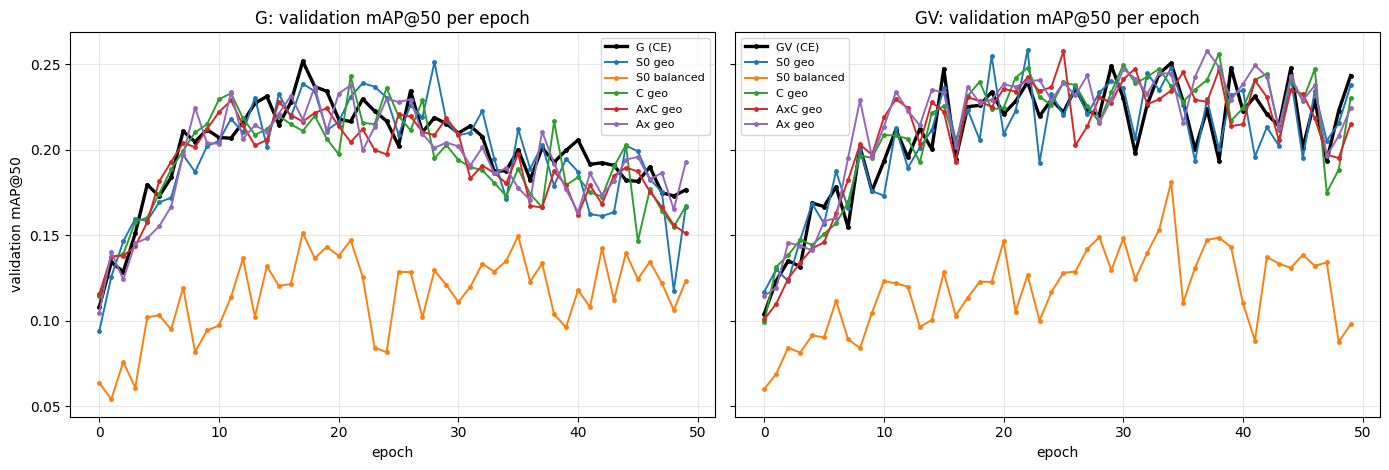

saved v5_best.csv, v5_history.csv, v5_map50.png in F:\runs


In [10]:
import matplotlib.pyplot as plt
# one row per run: detection metrics + Sat / CE values of the knowledge base at its best epoch
rows, hist_rows = [], []
for b in BASES:
    runs = [(f"{b} (CE)", BASES[b])] + [(f"{s} {a}", run_name(b, s, a)) for s in ("S0", "C", "AxC", "Ax")
                                         for a in ("geo", "balanced")]
    for label, rn in runs:
        if not os.path.exists(os.path.join(OUT_ROOT, rn, "history.json")):
            continue
        row = summary_row(label, rn, b)
        bb = max(hist(rn), key=lambda r: r["val/map_50"])
        row.update({k[4:]: v for k, v in bb.items() if k.startswith(("val/sat_", "val/ce_attr")) or k == "val/ce_class"})
        rows.append(row)
        for r in hist(rn):
            hist_rows.append({"run": label, "base": b, **{k: v for k, v in r.items() if isinstance(v, (int, float))}})
best = pd.DataFrame(rows)
# deltas against the cross-entropy baseline of the same base
ref_m = best[best.run.str.endswith("(CE)")].set_index("base")
for k in ("mAP50_best", "mAP50_mean", "FROCcalc_mean", "AUC_mean"):
    best[f"d_{k}"] = best.apply(lambda r: r[k] - ref_m.loc[r.base, k], axis=1)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 80)
cols = ["base", "run", "best_epoch", "mAP50_best", "d_mAP50_best", "mAP50_mean", "d_mAP50_mean", "FROCmass_mean",
        "FROCcalc_mean", "d_FROCcalc_mean", "AUC_mean", "det_mean"]
display(best[cols].round(4))
sat_cols = [c for c in best.columns if c.startswith(("sat_", "ce_"))]
display(best.assign(run=best.base + " " + best.run).set_index("run")[sat_cols].T.round(3))
best.to_csv(os.path.join(OUT_ROOT, "v5_best.csv"), index=False)
hd = pd.DataFrame(hist_rows); hd.to_csv(os.path.join(OUT_ROOT, "v5_history.csv"), index=False)

# validation mAP@50 per epoch, one panel per base
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, b in zip(axes, BASES):
    for label, g in hd[hd.base == b].groupby("run", sort=False):
        ax.plot(g["epoch"], g["val/map_50"], marker="o", ms=2.5, lw=1.4 if "(CE)" not in label else 2.4,
                color="black" if "(CE)" in label else None, label=label)
    ax.set_title(f"{b}: validation mAP@50 per epoch"); ax.set_xlabel("epoch"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("validation mAP@50")
fig.tight_layout(); fig.savefig(os.path.join(OUT_ROOT, "v5_map50.png"), dpi=150); plt.show()
print("saved v5_best.csv, v5_history.csv, v5_map50.png in", OUT_ROOT)

## 10. Concept evaluation and examples (validation split, ~10–15 min on the GPU)
`ltn_examples_and_concepts.py` (put it in `CODE_DIR`) loads the `best.pt` of C, AxC, Ax on G and G+V; nothing is
trained, the test split is never read.
* every validation lesion is matched to the best detection with IoU ≥ 0.5; on those: accuracy / macro-F1 of every
  concept head against the majority baseline, class and malignancy accuracy;
* every axiom of kb16 on the **predictions**: `sat` (as in training), `sat_label` (family fixed by the lesion: not
  vacuous for the calcification axioms), `violated` (share of the axiom's lesions with truth < 0.5), `follows` (where
  the predicted antecedent holds, share predicted as the consequent);
* example pages: AxC vs C on G, the same 16 images.

Send `concept_eval.csv`, `axiom_eval.csv` and the two `*_examples.pdf` (folder `F:\runs\ltn_examples_v5`).

In [6]:
# 10a. checks + a copy of the script with the paths of this notebook (the original is not changed)
import re
EVAL_SCRIPT = os.path.join(CODE_DIR, "ltn_examples_and_concepts.py")
EVAL_OUT    = os.path.join(OUT_ROOT, "ltn_examples_v5")
EVAL_RUN    = os.path.join(EVAL_OUT, "_run_eval_v5.py")
assert os.path.exists(EVAL_SCRIPT), f"copy ltn_examples_and_concepts.py into {CODE_DIR}"
AGG = json.load(open(os.path.join(OUT_ROOT, "v5_chosen_aggregator.json")))["chosen"]
assert AGG == "geo", f"the script evaluates the geo runs, chosen aggregator is {AGG}"
for b in BASES:
    for s in ("C", "AxC", "Ax"):
        rn = run_name(b, s, AGG)
        print(f"  {rn:22s}", "best.pt ok" if os.path.exists(os.path.join(OUT_ROOT, rn, "best.pt")) else "MISSING (skipped)")
src = open(EVAL_SCRIPT, encoding="utf-8").read()
for var, val in (("CODE_DIR", CODE_DIR), ("DATA_ROOT", DATA_ROOT), ("RUNS", OUT_ROOT)):
    src, n = re.subn(rf'^{var} = r".*?"', lambda _m, v=var, x=val: f'{v} = r"{x}"', src, count=1, flags=re.M)
    assert n == 1, f"{var} line not found in the script"
os.makedirs(EVAL_OUT, exist_ok=True)
open(EVAL_RUN, "w", encoding="utf-8").write(src)
print("script copy ->", EVAL_RUN)
try:                                                             # shared GPU: only look
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.used,memory.total,utilization.gpu", "--format=csv"],
                         capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not found")

  v5_G_C_geo_e50         best.pt ok
  v5_G_AxC_geo_e50       best.pt ok
  v5_G_Ax_geo_e50        best.pt ok
  v5_GV_C_geo_e50        best.pt ok
  v5_GV_AxC_geo_e50      best.pt ok
  v5_GV_Ax_geo_e50       best.pt ok
script copy -> F:\runs\ltn_examples_v5\_run_eval_v5.py
name, memory.used [MiB], memory.total [MiB], utilization.gpu [%]
NVIDIA GeForce RTX 3090, 1448 MiB, 24576 MiB, 30 %



In [7]:
# 10b. run (output streams here)
t0 = time.time()
proc = subprocess.Popen([sys.executable, "-u", EVAL_RUN], cwd=CODE_DIR, stdout=subprocess.PIPE,
                        stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
for line in proc.stdout:
    print(line, end="")
proc.wait()
print(f"\nexit code {proc.returncode}, {(time.time() - t0) / 60:.1f} min")
assert proc.returncode == 0, "the evaluation failed: send the last lines above"

401 validation images, 438 lesions
C G: detected 0.578, class acc 0.715, malignancy acc 0.636
   examples -> F:\runs\ltn_examples_v5\v5_G_C_geo_e50_examples.pdf
AxC G: detected 0.589, class acc 0.740, malignancy acc 0.640
   examples -> F:\runs\ltn_examples_v5\v5_G_AxC_geo_e50_examples.pdf
Ax G: detected 0.589, class acc 0.667, malignancy acc 0.601
C GV: detected 0.660, class acc 0.723, malignancy acc 0.637
AxC GV: detected 0.639, class acc 0.686, malignancy acc 0.657
Ax GV: detected 0.612, class acc 0.769, malignancy acc 0.653

Sat of every axiom on the matched validation detections, as in training (ApME p=2):
run     Ax G  Ax GV  AxC G  AxC GV    C G   C GV
axiom                                           
psi3   0.923  0.887  0.859   0.893  0.906  0.892
psi4   0.935  0.955  0.964   0.966  0.939  0.933
psi5   0.940  0.956  0.952   0.950  0.912  0.900
psi6   0.964  0.974  0.952   0.930  0.911  0.905
psi7   0.958  0.971  0.971   0.970  0.960  0.966
psi8   0.956  0.969  0.941   0.911  0.

In [8]:
# 10c. concept heads on the detected validation lesions, and the difference against C of the same base
ce = pd.read_csv(os.path.join(EVAL_OUT, "concept_eval.csv"))
ce["model"], ce["base"] = ce["run"].str.split().str[0], ce["run"].str.split().str[1]
display(ce.set_index("run").drop(columns=["folder", "model", "base"]).T.round(3))
num = [c for c in ce.columns if c not in ("run", "folder", "model", "base", "best_epoch", "lesions")]
rows = []
for b, d in ce.groupby("base"):
    d = d.set_index("model")
    for m in ("AxC", "Ax"):
        if m in d.index and "C" in d.index:
            rows.append(pd.Series(d.loc[m, num].astype(float) - d.loc["C", num].astype(float), name=f"{m} - C ({b})"))
if rows:
    print("Difference against C (positive = better with the axioms; 'majority baseline' rows must be ~0):")
    display(pd.DataFrame(rows).T.round(3))

run,C G,AxC G,Ax G,C GV,AxC GV,Ax GV
best_epoch,21.000,11.000,21.000,38.000,25.000,37.000
mAP50,0.243,0.229,0.238,0.256,0.258,0.258
lesions,438.000,438.000,438.000,438.000,438.000,438.000
detected (IoU >= 0.5),0.578,0.589,0.589,0.660,0.639,0.612
class accuracy,0.715,0.740,0.667,0.723,0.686,0.769
malignancy accuracy,0.636,0.640,0.601,0.637,0.657,0.653
mass_shape accuracy,0.697,0.570,0.078,0.714,0.691,0.078
mass_shape macro-F1,0.457,0.242,0.048,0.462,0.436,0.048
mass_shape majority baseline,0.572,0.570,0.582,0.578,0.586,0.571
mass_margin accuracy (per value),0.782,0.785,0.781,0.785,0.784,0.784


Difference against C (positive = better with the axioms; 'majority baseline' rows must be ~0):


,AxC - C (G),Ax - C (G),AxC - C (GV),Ax - C (GV)
mAP50,-0.014,-0.005,0.001,0.002
detected (IoU >= 0.5),0.011,0.011,-0.021,-0.048
class accuracy,0.025,-0.049,-0.037,0.045
malignancy accuracy,0.003,-0.036,0.020,0.016
mass_shape accuracy,-0.126,-0.618,-0.023,-0.636
mass_shape macro-F1,-0.215,-0.409,-0.027,-0.414
mass_shape majority baseline,-0.002,0.009,0.008,-0.006
mass_margin accuracy (per value),0.003,-0.000,-0.001,-0.001
mass_margin macro-F1,0.000,0.000,-0.008,-0.008
mass_margin majority baseline,0.003,-0.000,0.001,0.000


In [9]:
# 10d. the axioms of kb16 on the predictions
ax = pd.read_csv(os.path.join(EVAL_OUT, "axiom_eval.csv"))
order = list(dict.fromkeys(ax["axiom"]))
rcols = [f"{m} {b}" for b in ("G", "GV") for m in ("C", "AxC", "Ax") if f"{m} {b}" in set(ax["run"])]
print(ax.drop_duplicates("axiom").set_index("axiom")[["rule", "domain", "domain_family"]].to_string(), "\n")
for v, what in (("sat", "Sat as in training (paper, Diag guard on the class)"),
                ("sat_label", "Sat with the family fixed by the lesion (not vacuous)"),
                ("violated", "share of the axiom's lesions that VIOLATE it (lower = better)"),
                ("follows", "where the predicted antecedent holds: share predicted as the consequent"),
                ("antecedent_true", "detected lesions whose predicted antecedent holds")):
    print(f"--- {v}: {what}")
    display(ax.pivot(index="axiom", columns="run", values=v).reindex(index=order, columns=rcols).round(3))
rows = {}
for b in BASES:
    for m in ("AxC", "Ax"):
        a, c = ax[ax["run"] == f"{m} {b}"].set_index("axiom"), ax[ax["run"] == f"C {b}"].set_index("axiom")
        if len(a) and len(c):
            for v in ("sat_label", "violated", "follows"):
                rows[(f"{m} - C ({b})", v)] = a[v] - c[v]
if rows:
    print("Difference against C per axiom:")
    display(pd.DataFrame(rows).reindex(order).round(3))

send = ["concept_eval.csv", "axiom_eval.csv"] + sorted(os.path.basename(p) for p in glob.glob(os.path.join(EVAL_OUT, "*_examples.pdf")))
print("\nsend:", send, "\nfolder:", EVAL_OUT)
if os.name == "nt":
    os.startfile(EVAL_OUT)

                                                 rule  domain  domain_family
axiom                                                                       
psi3            mass circumscribed/obscured -> benign     121             72
psi4                 mass microlobulated -> malignant     132             86
psi5                     mass indistinct -> malignant     132             86
psi6                      mass irregular -> malignant     132             86
psi7     amorphous, not regional/diffuse -> malignant     132             46
psi8   pleomorphic, not regional/diffuse -> malignant     132             46
psi9                   mass high density -> malignant     132             86
psi10                    mass spiculated -> malignant     132             86
psi11            fine linear + segmental -> malignant     132             46
psi12               fine linear + linear -> malignant     132             46
psi13  coarse het., not regional/diffuse -> malignant     132             46

run,C G,AxC G,Ax G,C GV,AxC GV,Ax GV
axiom,,,,,,
psi3,0.906,0.859,0.923,0.892,0.893,0.887
psi4,0.939,0.964,0.935,0.933,0.966,0.955
psi5,0.912,0.952,0.940,0.900,0.950,0.956
psi6,0.911,0.952,0.964,0.905,0.930,0.974
psi7,0.960,0.971,0.958,0.966,0.970,0.971
psi8,0.888,0.941,0.956,0.900,0.911,0.969
psi9,0.930,0.948,0.956,0.912,0.939,0.969
psi10,0.910,0.952,0.936,0.899,0.948,0.954
psi11,0.998,0.998,0.986,0.999,0.999,0.990


--- sat_label: Sat with the family fixed by the lesion (not vacuous)


run,C G,AxC G,Ax G,C GV,AxC GV,Ax GV
axiom,,,,,,
psi3,0.749,0.737,0.759,0.746,0.785,0.753
psi4,0.858,0.905,0.827,0.864,0.903,0.871
psi5,0.794,0.875,0.842,0.792,0.850,0.869
psi6,0.755,0.875,0.904,0.770,0.793,0.923
psi7,0.851,0.847,0.835,0.854,0.887,0.850
psi8,0.605,0.688,0.831,0.597,0.671,0.847
psi9,0.813,0.868,0.871,0.827,0.854,0.903
psi10,0.786,0.874,0.828,0.789,0.852,0.868
psi11,0.994,0.991,0.943,0.994,0.995,0.952


--- violated: share of the axiom's lesions that VIOLATE it (lower = better)


run,C G,AxC G,Ax G,C GV,AxC GV,Ax GV
axiom,,,,,,
psi3,0.028,0.013,0.065,0.012,0.000,0.0
psi4,0.000,0.000,0.000,0.000,0.000,0.0
psi5,0.000,0.000,0.000,0.000,0.000,0.0
psi6,0.023,0.000,0.000,0.021,0.011,0.0
psi7,0.000,0.000,0.000,0.000,0.000,0.0
psi8,0.043,0.000,0.000,0.117,0.000,0.0
psi9,0.012,0.000,0.000,0.000,0.000,0.0
psi10,0.000,0.000,0.000,0.000,0.000,0.0
psi11,0.000,0.000,0.000,0.000,0.000,0.0


... (3 outputs left out)

run,C G,AxC G,Ax G,C GV,AxC GV,Ax GV
axiom,,,,,,
psi3,121,9,54,144,2,26
psi4,0,0,0,0,0,0
psi5,0,0,0,0,0,0
psi6,37,0,0,40,35,0
psi7,0,0,0,0,0,0
psi8,30,0,0,42,0,0
psi9,24,19,0,36,27,0
psi10,0,0,0,0,0,0
psi11,0,0,0,0,0,0


Difference against C per axiom:


AxC - C (G)                  Ax - C (G)                  AxC - C (GV)  \
        sat_label violated follows  sat_label violated follows    sat_label   
axiom                                                                         
psi3       -0.012   -0.014  -0.504      0.010    0.037  -0.467        0.039   
psi4        0.047    0.000     NaN     -0.031    0.000     NaN        0.038   
psi5        0.080    0.000     NaN      0.048    0.000     NaN        0.058   
psi6        0.120   -0.023     NaN      0.150   -0.023     NaN        0.023   
psi7       -0.004    0.000     NaN     -0.016    0.000     NaN        0.033   
psi8        0.082   -0.043     NaN      0.226   -0.043     NaN        0.074   
psi9        0.054   -0.012   0.208      0.057   -0.012     NaN        0.027   
psi10       0.088    0.000     NaN      0.042    0.000     NaN        0.063   
psi11      -0.004    0.000     NaN     -0.052    0.000     NaN        0.001   
psi12      -0.003    0.000     NaN     -0.042    0.000     NaN        0.002   
psi13      -0.019    0.000     NaN     -0.054    0.000     NaN        0.018   
psi14      -0.012    0.000     NaN      0.063    0.000     NaN        0.016   
psi16      -0.013    0.000     NaN     -0.073    0.000     NaN        0.000   

                       Ax - C (GV)                   
      violated follows   sat_label violated follows  
axiom                                                
psi3    -0.012  -0.028       0.007   -0.012  -0.528  
psi4     0.000     NaN       0.007    0.000     NaN  
psi5     0.000     NaN       0.078    0.000     NaN  
psi6    -0.010  -0.007       0.152   -0.021     NaN  
psi7     0.000     NaN      -0.004    0.000     NaN  
psi8    -0.117     NaN       0.249   -0.117     NaN  
psi9     0.000   0.139       0.076    0.000     NaN  
psi10    0.000     NaN       0.079    0.000     NaN  
psi11    0.000     NaN      -0.042    0.000     NaN  
psi12    0.000     NaN      -0.036    0.000     NaN  
psi13    0.000     NaN      -0.041    0.000     NaN  
psi14    0.000     NaN       0.059    0.000     NaN  
psi16    0.000     NaN      -0.067    0.000     NaN


send: ['concept_eval.csv', 'axiom_eval.csv', 'v5_G_AxC_geo_e50_examples.pdf', 'v5_G_C_geo_e50_examples.pdf'] 
folder: F:\runs\ltn_examples_v5


## Summary

In [11]:
print(f"tests: {globals().get('N1', '?')} (logic and facts) + {globals().get('N2', '?')} (heads) passed")
print("facts file:", FACTS_FILE, "exists" if os.path.exists(FACTS_FILE) else "MISSING")
print("runs:", sorted(os.path.basename(os.path.dirname(p)) for p in glob.glob(os.path.join(OUT_ROOT, "v5_*", "best.pt"))))

tests: 47 (logic and facts) + 12 (heads) passed
facts file: F:\runs\facts_v5\facts_v5.csv exists
runs: ['v5_GV_AxC_geo_e50', 'v5_GV_Ax_geo_e50', 'v5_GV_C_geo_e50', 'v5_GV_S0_balanced_e50', 'v5_GV_S0_geo_e50', 'v5_G_AxC_geo_e50', 'v5_G_Ax_geo_e50', 'v5_G_C_geo_e50', 'v5_G_S0_balanced_e50', 'v5_G_S0_geo_e50', 'v5_smoke_AxC_bal_e1', 'v5_smoke_S0_geo_e1']
